In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Зареждане
df = pd.read_csv(
    "data/traffic_combined.csv",
    parse_dates=["date"],
    low_memory=False
)

In [3]:
print(f"Редове  : {len(df):,}")
print(f"Колони  : {len(df.columns)}")
print(f"Памет   : {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"Период  : {df['date'].min()}  →  {df['date'].max()}")
print(f"\nКолони  : {list(df.columns)}")
print(f"\nТипове данни:\n{df.dtypes}")

Редове  : 12,239,528
Колони  : 9
Памет   : 3112.0 MB
Период  : 2022-01-01 00:00:18  →  2024-12-31 23:59:06

Колони  : ['date', 'direction', 'plate', 'country', 'speed', 'vehicle_class', 'lane', 'length', 'weight']

Типове данни:
date             datetime64[us]
direction                   str
plate                       str
country                     str
speed                     int64
vehicle_class             int64
lane                        str
length                    int64
weight                    int64
dtype: object


In [4]:
null_info = pd.DataFrame({
    "dtype"   : df.dtypes,
    "non_null": df.count(),
    "null"    : df.isnull().sum(),
    "null_%"  : (df.isnull().sum() / len(df) * 100).round(3)
})

print(null_info)

                        dtype  non_null     null  null_%
date           datetime64[us]  12239528        0   0.000
direction                 str  11801959   437569   3.575
plate                     str   9094719  3144809  25.694
country                   str   7347794  4891734  39.967
speed                   int64  12239528        0   0.000
vehicle_class           int64  12239528        0   0.000
lane                      str  12239528        0   0.000
length                  int64  12239528        0   0.000
weight                  int64  12239528        0   0.000


In [5]:
print(df[["speed", "length", "weight"]].describe().round(2))

             speed       length       weight
count  12239528.00  12239528.00  12239528.00
mean         47.84      4114.22      2345.07
std          13.77      2172.54      4437.06
min           0.00   -707100.00   -392960.00
25%          42.00      3200.00       998.00
50%          47.00      3900.00      1444.00
75%          53.00      4610.00      2463.00
max         255.00    318800.00    907790.00


In [6]:
for col in ["direction", "vehicle_class", "lane", "country"]:
    n_unique = df[col].nunique()
    print(f"\n── {col.upper()} ({n_unique} уникални) ──")
    print(df[col].value_counts().head(10).to_string())


── DIRECTION (2 уникални) ──
direction
Център          6316226
Околовръстно    5485733

── VEHICLE_CLASS (38 уникални) ──
vehicle_class
1     9740789
0      977197
2      668345
5      222459
7      220750
6      203298
3      186179
4       15443
23       2618
30        491

── LANE (10 уникални) ──
lane
L2     4077166
L5     3514639
L1     1475592
L4     1070725
L6      900369
L3      763468
LN2     196996
LN5     166816
LN3      38075
LN6      35682

── COUNTRY (78 уникални) ──
country
BG     5714389
BGR    1139232
-       190835
UA       67078
DE       29906
AT       26699
GB       21326
DK       21265
TR       16173
FR       15143


In [7]:
df["year"]  = df["date"].dt.year
df["month"] = df["date"].dt.month
df["hour"]  = df["date"].dt.hour
df["dow"]   = df["date"].dt.dayofweek  # 0=Пон, 6=Нед

print("По година:")
print(df["year"].value_counts().sort_index().to_string())

print("\nПо месец:")
print(df["month"].value_counts().sort_index().to_string())

print("\nПо час:")
print(df["hour"].value_counts().sort_index().to_string())

По година:
year
2022    3266248
2023    6836744
2024    2136536

По месец:
month
1     1027219
2      854890
3     1803709
4     1046364
5      683256
6     1411367
7      431995
8      646566
9      637446
10    1056578
11     949973
12    1690165

По час:
hour
0     150177
1      88083
2      69775
3      72529
4      89994
5     135088
6     253159
7     615797
8     650194
9     636014
10    694764
11    777428
12    815480
13    829352
14    829190
15    838616
16    891625
17    948173
18    865073
19    708961
20    505193
21    339382
22    234550
23    200931


In [8]:
# Агрегиране по час
df_hourly = df.groupby(df["date"].dt.floor("h")).size().reset_index()
df_hourly.columns = ["hour_ts", "count"]
df_hourly = df_hourly.set_index("hour_ts")

# Пълна почасова поредица
full_range = pd.date_range(
    start=df["date"].min().floor("h"),
    end=df["date"].max().floor("h"),
    freq="h"
)

# Часове без нито един запис
missing_hours = full_range.difference(df_hourly.index)

print(f"Часове в пълния диапазон : {len(full_range):,}")
print(f"Часове с данни           : {len(df_hourly):,}")
print(f"Часове без нито 1 запис  : {len(missing_hours):,}  "
      f"({len(missing_hours)/len(full_range)*100:.1f}%)")

# Намиране на последователни gaps
missing_series = pd.Series(1, index=missing_hours).reindex(full_range, fill_value=0)

in_gap = False
gaps = []
gap_start = None

for ts, val in missing_series.items():
    if val == 1 and not in_gap:
        gap_start = ts
        in_gap = True
    elif val == 0 and in_gap:
        gaps.append({
            "start": gap_start,
            "end"  : ts,
            "hours": int((ts - gap_start).total_seconds() / 3600)
        })
        in_gap = False

if in_gap:
    gaps.append({
        "start": gap_start,
        "end"  : full_range[-1],
        "hours": int((full_range[-1] - gap_start).total_seconds() / 3600)
    })

gaps_df = pd.DataFrame(gaps).sort_values("hours", ascending=False).reset_index(drop=True)

# Разпределение по категория
bins   = [0, 1, 6, 24, 72, 168, 720, float("inf")]
labels = ["<=1h", "1-6h", "6-24h", "1-3 дни", "3-7 дни", "1-4 седмици", ">1 месец"]
gaps_df["category"] = pd.cut(gaps_df["hours"], bins=bins, labels=labels)

print(f"\nОбщо gap-ове: {len(gaps_df):,}")
print(f"\nРазпределение по продължителност:")
print(gaps_df["category"].value_counts().sort_index().to_string())

print(f"\nВсички gap-ове (наредени по продължителност):")
pd.set_option("display.max_rows", None)
print(gaps_df.to_string(index=True))
pd.reset_option("display.max_rows")

Часове в пълния диапазон : 26,304
Часове с данни           : 18,462
Часове без нито 1 запис  : 7,842  (29.8%)

Общо gap-ове: 98

Разпределение по продължителност:
category
<=1h           20
1-6h           22
6-24h          32
1-3 дни        11
3-7 дни         4
1-4 седмици     5
>1 месец        4

Всички gap-ове (наредени по продължителност):
                 start                 end  hours     category
0  2022-10-01 03:00:00 2022-11-25 15:00:00   1332     >1 месец
1  2024-08-17 09:00:00 2024-10-09 15:00:00   1278     >1 месец
2  2022-12-10 15:00:00 2023-01-20 13:00:00    982     >1 месец
3  2024-10-25 19:00:00 2024-11-28 15:00:00    812     >1 месец
4  2024-02-09 21:00:00 2024-03-05 17:00:00    596  1-4 седмици
5  2022-05-16 17:00:00 2022-06-06 11:00:00    498  1-4 седмици
6  2022-03-18 06:00:00 2022-04-06 13:00:00    463  1-4 седмици
7  2023-05-08 01:00:00 2023-05-19 15:00:00    278  1-4 седмици
8  2022-07-17 01:00:00 2022-07-28 15:00:00    278  1-4 седмици
9  2023-02-16 19:00:00 20

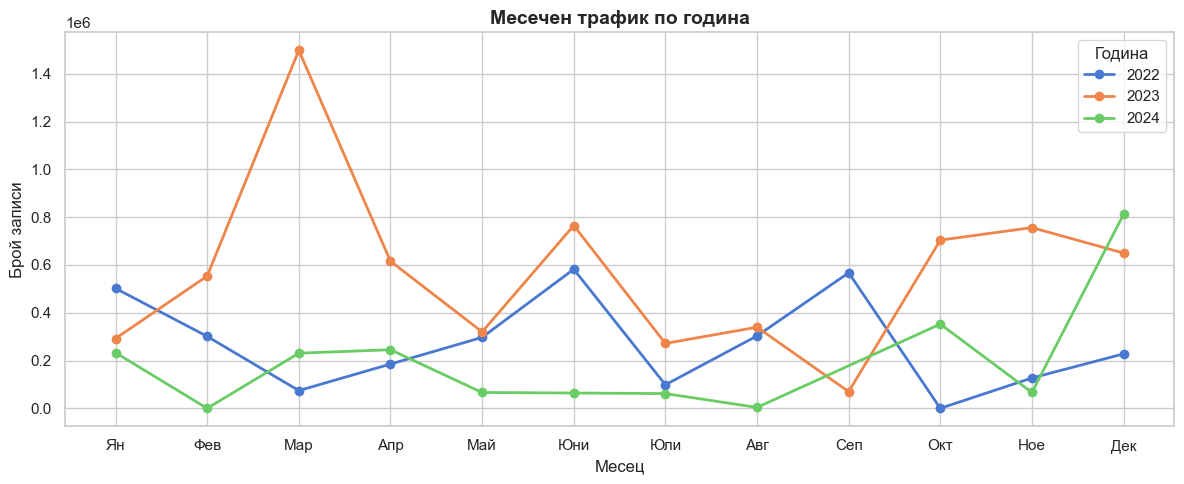

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

# --- Визуализация 1: Месечен трафик по година ---
monthly = df.groupby(["year", "month"]).size().reset_index(name="count")

fig, ax = plt.subplots(figsize=(12, 5))

for yr in sorted(monthly["year"].unique()):
    sub = monthly[monthly["year"] == yr]
    ax.plot(sub["month"], sub["count"], marker="o", label=str(yr), linewidth=2)

ax.set_title("Месечен трафик по година", fontsize=14, fontweight="bold")
ax.set_xlabel("Месец")
ax.set_ylabel("Брой записи")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ян","Фев","Мар","Апр","Май","Юни","Юли","Авг","Сеп","Окт","Ное","Дек"])
ax.legend(title="Година")

plt.tight_layout()
plt.savefig("viz_01_monthly_traffic.png", dpi=150, bbox_inches="tight")
plt.show()

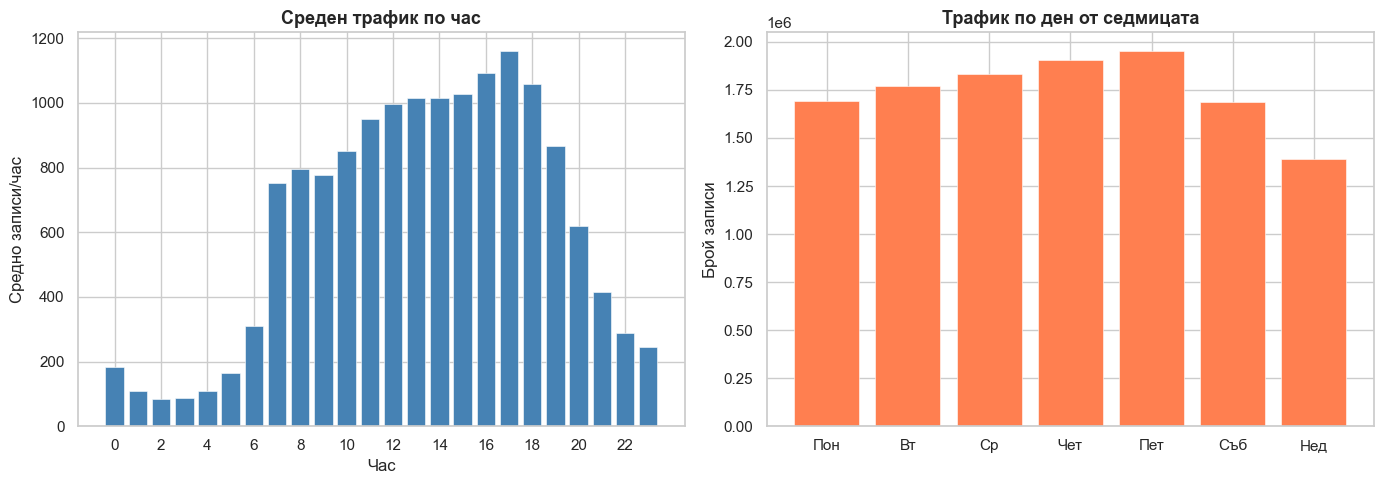

In [10]:
# --- Визуализация 2: Почасов трафик + Ден от седмицата ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Почасов трафик
df["date_only"] = df["date"].dt.date
hourly_avg = df.groupby("hour").size() / df["date_only"].nunique()
ax1.bar(hourly_avg.index, hourly_avg.values, color="steelblue", edgecolor="white", linewidth=0.4)
ax1.set_title("Среден трафик по час", fontsize=13, fontweight="bold")
ax1.set_xlabel("Час")
ax1.set_ylabel("Средно записи/час")
ax1.set_xticks(range(0, 24, 2))

# Ден от седмицата
dow_counts = df.groupby("dow").size()
dow_labels = ["Пон","Вт","Ср","Чет","Пет","Съб","Нед"]
ax2.bar(dow_labels, dow_counts.values, color="coral", edgecolor="white", linewidth=0.4)
ax2.set_title("Трафик по ден от седмицата", fontsize=13, fontweight="bold")
ax2.set_ylabel("Брой записи")

plt.tight_layout()
plt.savefig("viz_02_hourly_dow.png", dpi=150, bbox_inches="tight")
plt.show()

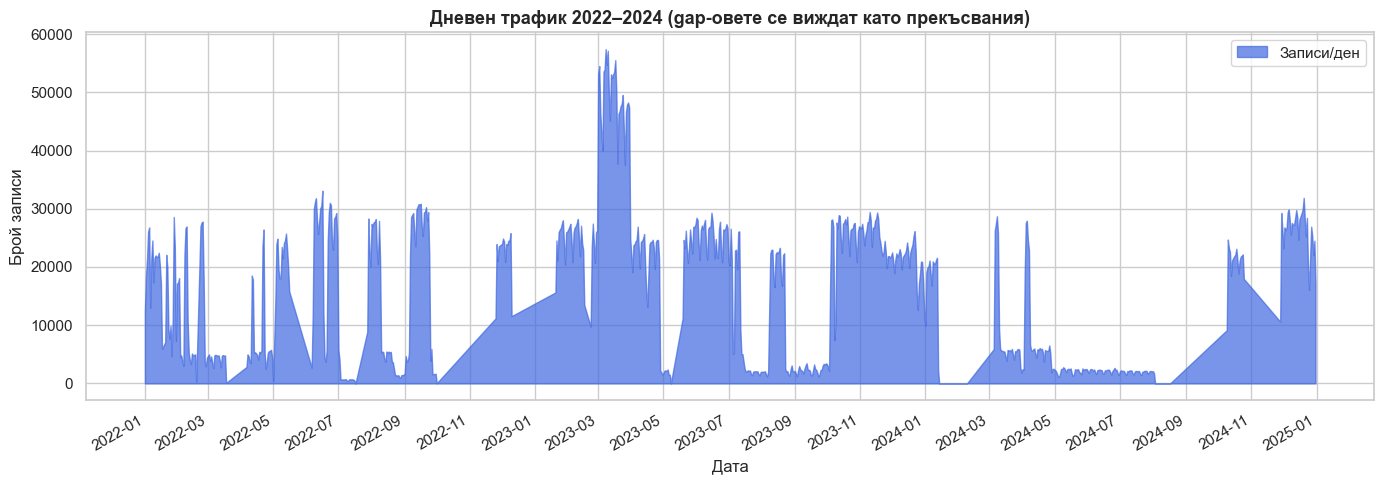

In [11]:
# --- Визуализация 3: Дневен трафик с видими gap-ове ---
fig, ax = plt.subplots(figsize=(14, 5))

daily_counts = df.groupby("date_only").size()
daily_index  = pd.to_datetime(list(daily_counts.index))

ax.fill_between(daily_index, daily_counts.values, alpha=0.7, 
                color="royalblue", label="Записи/ден")

ax.set_title("Дневен трафик 2022–2024 (gap-овете се виждат като прекъсвания)", 
             fontsize=13, fontweight="bold")
ax.set_xlabel("Дата")
ax.set_ylabel("Брой записи")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")
ax.legend()

plt.tight_layout()
plt.savefig("viz_03_daily_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

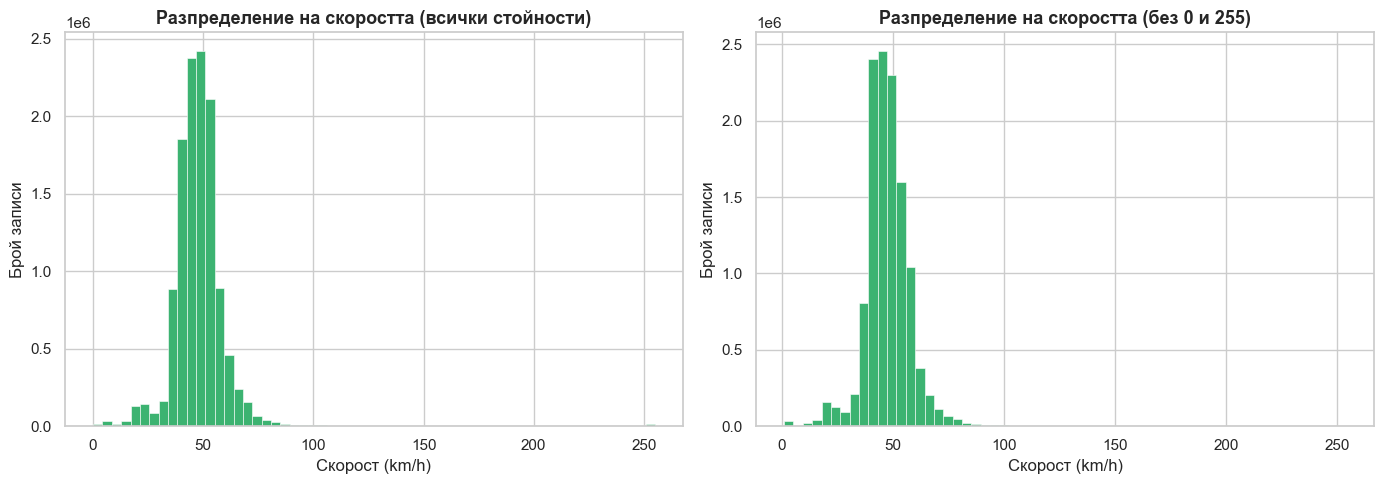

Speed = 0   : 17,276 записа (0.14%)
Speed = 255 : 15,387 записа (0.13%)


In [12]:
# --- Визуализация 4: Разпределение на скоростта ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Ляво — цялото разпределение
ax1.hist(df["speed"], bins=60, color="mediumseagreen", edgecolor="white", linewidth=0.4)
ax1.set_title("Разпределение на скоростта (всички стойности)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Скорост (km/h)")
ax1.set_ylabel("Брой записи")

# Дясно — без екстремните стойности (0 и 255)
speed_clean = df["speed"][(df["speed"] > 0) & (df["speed"] < 255)]
ax2.hist(speed_clean, bins=60, color="mediumseagreen", edgecolor="white", linewidth=0.4)
ax2.set_title("Разпределение на скоростта (без 0 и 255)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Скорост (km/h)")
ax2.set_ylabel("Брой записи")

plt.tight_layout()
plt.savefig("viz_04_speed.png", dpi=150, bbox_inches="tight")
plt.show()

# Колко записа са точно 0 или 255
print(f"Speed = 0   : {(df['speed'] == 0).sum():,} записа ({(df['speed'] == 0).mean()*100:.2f}%)")
print(f"Speed = 255 : {(df['speed'] == 255).sum():,} записа ({(df['speed'] == 255).mean()*100:.2f}%)")

Length <= 0      : 213,801 записа (1.75%)
Length >= 30,000 : 3,025 записа (0.02%)
Weight <= 0      : 1,412,003 записа (11.54%)
Weight >= 50,000 : 18,974 записа (0.16%)


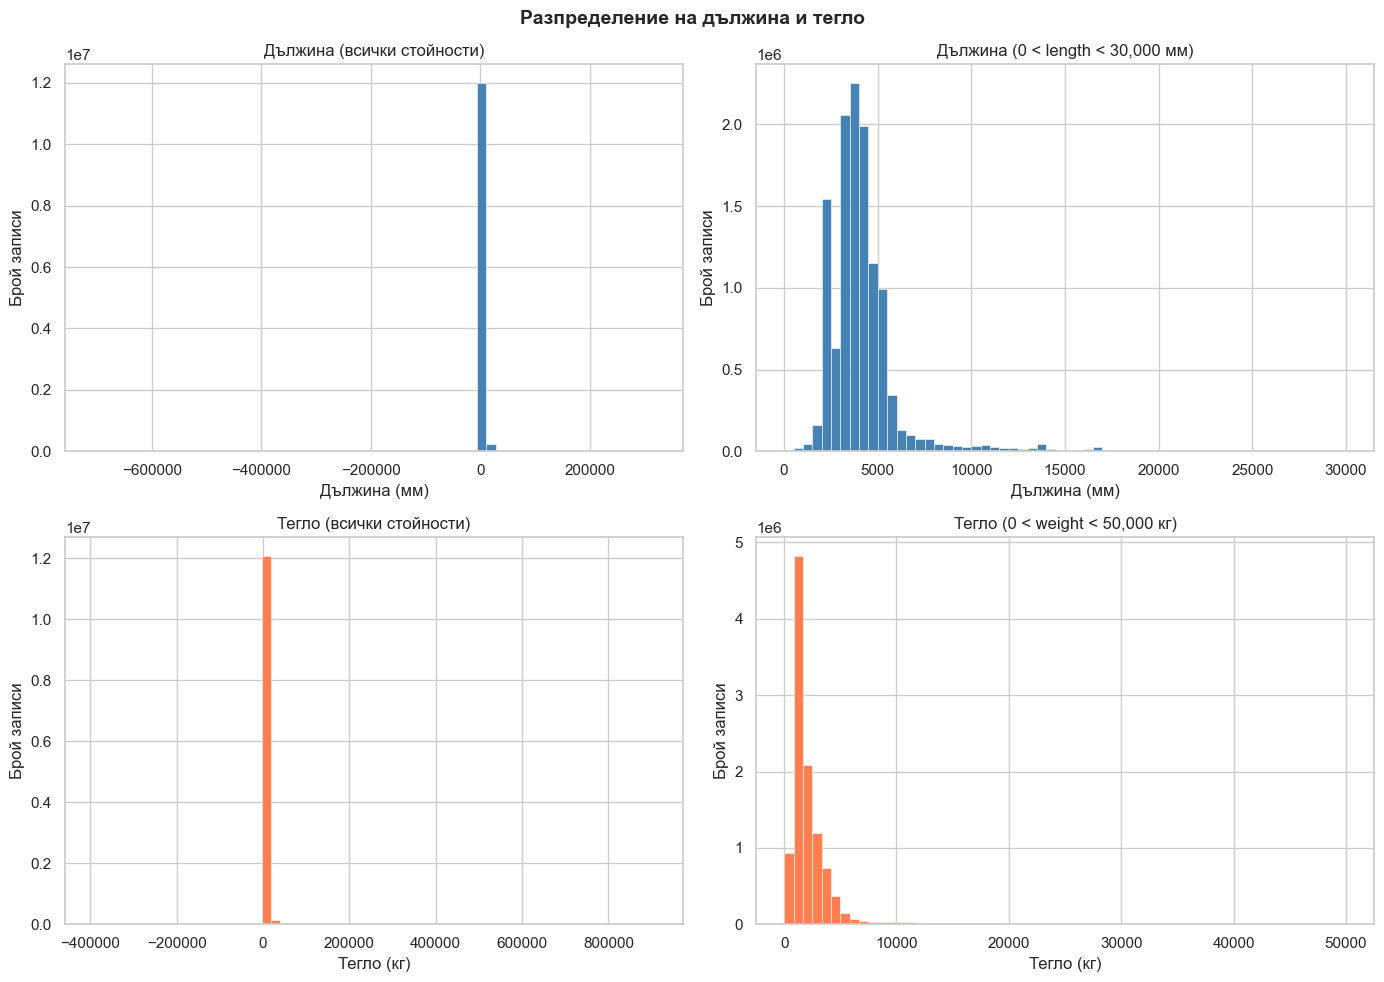

In [13]:
# --- Визуализация 5: Разпределение на length и weight ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Разпределение на дължина и тегло", fontsize=14, fontweight="bold")

# Length — всички стойности
axes[0, 0].hist(df["length"], bins=60, color="steelblue", edgecolor="white", linewidth=0.4)
axes[0, 0].set_title("Дължина (всички стойности)")
axes[0, 0].set_xlabel("Дължина (мм)")
axes[0, 0].set_ylabel("Брой записи")

# Length — без аномалии (0 < length < 30000 мм = 30м)
length_clean = df["length"][(df["length"] > 0) & (df["length"] < 30000)]
axes[0, 1].hist(length_clean, bins=60, color="steelblue", edgecolor="white", linewidth=0.4)
axes[0, 1].set_title("Дължина (0 < length < 30,000 мм)")
axes[0, 1].set_xlabel("Дължина (мм)")
axes[0, 1].set_ylabel("Брой записи")

# Weight — всички стойности
axes[1, 0].hist(df["weight"], bins=60, color="coral", edgecolor="white", linewidth=0.4)
axes[1, 0].set_title("Тегло (всички стойности)")
axes[1, 0].set_xlabel("Тегло (кг)")
axes[1, 0].set_ylabel("Брой записи")

# Weight — без аномалии (0 < weight < 50000 кг = 50 тона)
weight_clean = df["weight"][(df["weight"] > 0) & (df["weight"] < 50000)]
axes[1, 1].hist(weight_clean, bins=60, color="coral", edgecolor="white", linewidth=0.4)
axes[1, 1].set_title("Тегло (0 < weight < 50,000 кг)")
axes[1, 1].set_xlabel("Тегло (кг)")
axes[1, 1].set_ylabel("Брой записи")

# Статистика за аномалиите
print(f"Length <= 0      : {(df['length'] <= 0).sum():,} записа ({(df['length'] <= 0).mean()*100:.2f}%)")
print(f"Length >= 30,000 : {(df['length'] >= 30000).sum():,} записа ({(df['length'] >= 30000).mean()*100:.2f}%)")
print(f"Weight <= 0      : {(df['weight'] <= 0).sum():,} записа ({(df['weight'] <= 0).mean()*100:.2f}%)")
print(f"Weight >= 50,000 : {(df['weight'] >= 50000).sum():,} записа ({(df['weight'] >= 50000).mean()*100:.2f}%)")

plt.tight_layout()
plt.savefig("viz_05_length_weight.png", dpi=150, bbox_inches="tight")
plt.show()

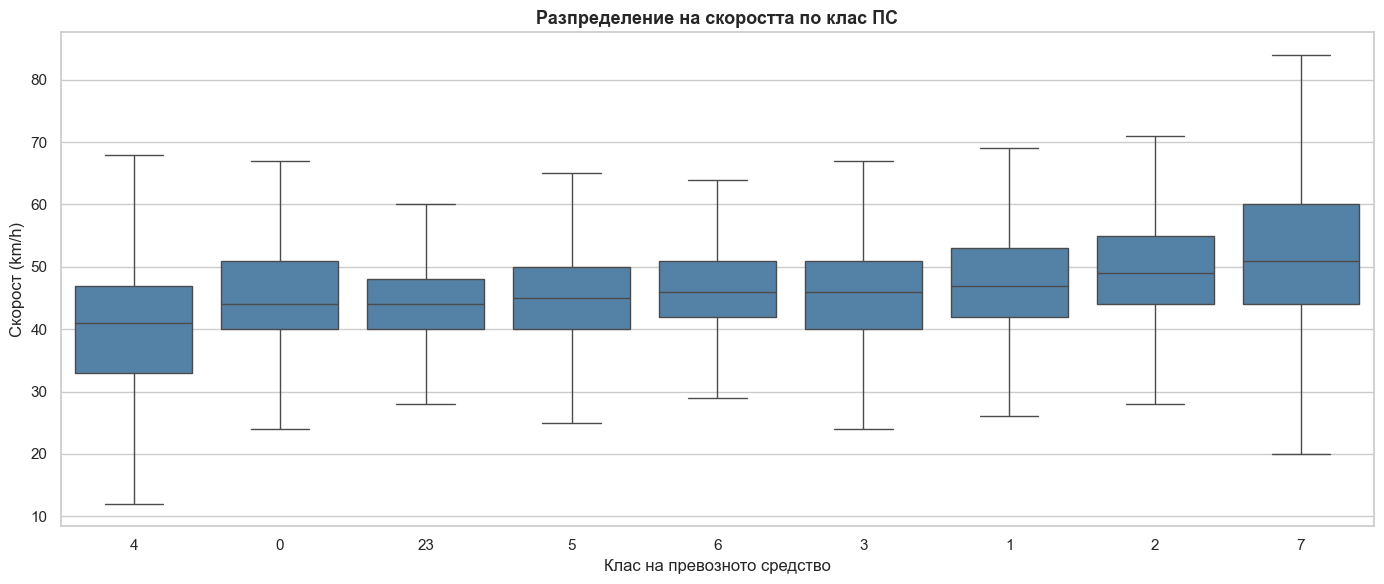

Медианна скорост по vehicle_class:
               median  mean    count
vehicle_class                       
4                41.0  39.1    15403
0                44.0  46.7   958599
23               44.0  44.3     2618
5                45.0  44.3   221444
6                46.0  46.3   202796
3                46.0  45.2   185067
1                47.0  47.6  9732951
2                49.0  49.8   667311
7                51.0  55.0   218226


In [14]:
# --- Визуализация 6: Boxplot скорост по vehicle_class ---
import seaborn as sns

speed_clean = df[(df["speed"] > 0) & (df["speed"] < 255)].copy()
class_counts = speed_clean["vehicle_class"].value_counts()
valid_classes = class_counts[class_counts > 1000].index
speed_filtered = speed_clean[speed_clean["vehicle_class"].isin(valid_classes)]

# Наредени по медиана
order = (speed_filtered.groupby("vehicle_class")["speed"]
         .median()
         .sort_values()
         .index
         .tolist())

fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data=speed_filtered,
    x="vehicle_class",
    y="speed",
    order=order,
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_title("Разпределение на скоростта по клас ПС", fontsize=13, fontweight="bold")
ax.set_xlabel("Клас на превозното средство")
ax.set_ylabel("Скорост (km/h)")

plt.tight_layout()
plt.savefig("viz_06_speed_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

# Медианна скорост по клас
print("Медианна скорост по vehicle_class:")
print(speed_filtered.groupby("vehicle_class")["speed"]
      .agg(["median", "mean", "count"])
      .sort_values("median")
      .round(1)
      .to_string())

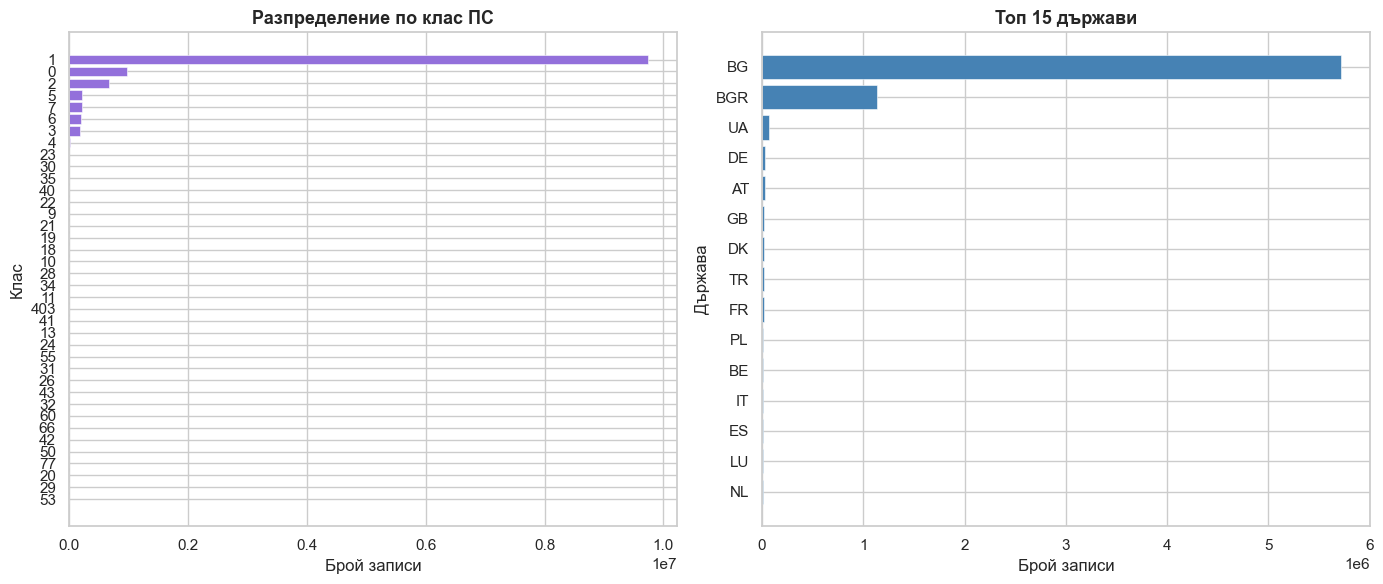

BG vs BGR:
  BG  : 5,714,389
  BGR : 1,139,232
  Общо: 6,853,621


In [15]:
# --- Визуализация 7: Vehicle class + Top countries ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Vehicle class разпределение
vc_counts = df["vehicle_class"].value_counts().sort_values(ascending=True)
ax1.barh(vc_counts.index.astype(str), vc_counts.values, 
         color="mediumpurple", edgecolor="white", linewidth=0.4)
ax1.set_title("Разпределение по клас ПС", fontsize=13, fontweight="bold")
ax1.set_xlabel("Брой записи")
ax1.set_ylabel("Клас")

# Топ държави (без BG/BGR за момента, после отделно)
country_counts = (df["country"]
                  .replace("-", pd.NA)
                  .dropna()
                  .value_counts()
                  .head(15)
                  .sort_values(ascending=True))

ax2.barh(country_counts.index, country_counts.values,
         color="steelblue", edgecolor="white", linewidth=0.4)
ax2.set_title("Топ 15 държави", fontsize=13, fontweight="bold")
ax2.set_xlabel("Брой записи")
ax2.set_ylabel("Държава")

plt.tight_layout()
plt.savefig("viz_07_class_country.png", dpi=150, bbox_inches="tight")
plt.show()

# BG vs BGR
print("BG vs BGR:")
print(f"  BG  : {(df['country'] == 'BG').sum():,}")
print(f"  BGR : {(df['country'] == 'BGR').sum():,}")
print(f"  Общо: {((df['country'] == 'BG') | (df['country'] == 'BGR')).sum():,}")

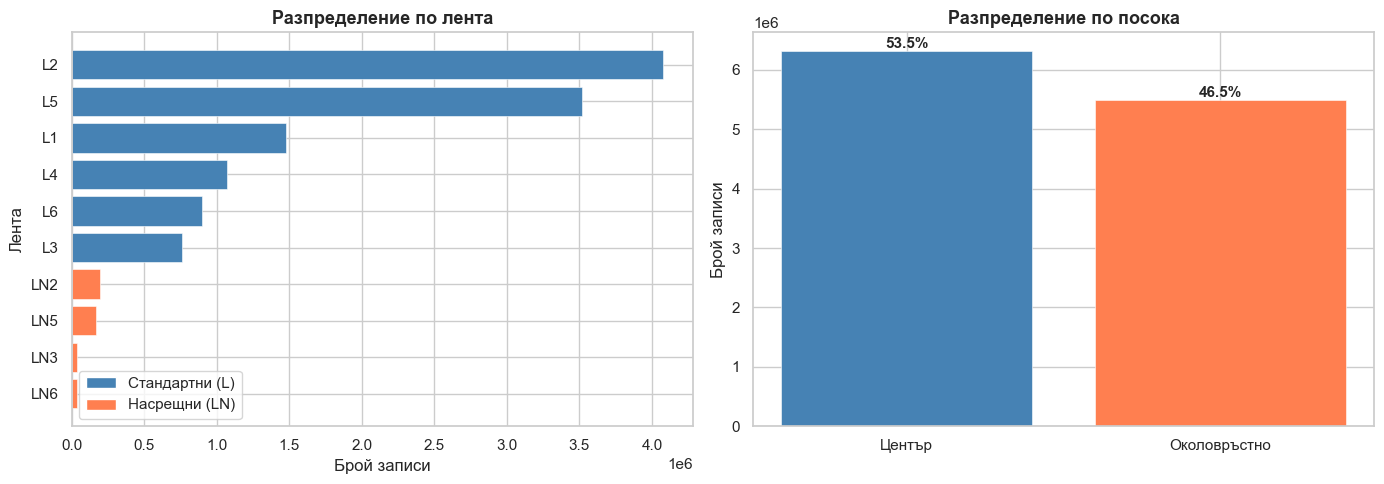

Записи по лента:
lane
L2     4077166
L5     3514639
L1     1475592
L4     1070725
L6      900369
L3      763468
LN2     196996
LN5     166816
LN3      38075
LN6      35682

Null в direction: 437,569


In [16]:
# --- Визуализация 8: Lane и Direction ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Lane разпределение
lane_counts = df["lane"].value_counts().sort_values(ascending=True)
colors = ["steelblue" if not str(l).startswith("LN") else "coral" 
          for l in lane_counts.index]
ax1.barh(lane_counts.index, lane_counts.values,
         color=colors, edgecolor="white", linewidth=0.4)
ax1.set_title("Разпределение по лента", fontsize=13, fontweight="bold")
ax1.set_xlabel("Брой записи")
ax1.set_ylabel("Лента")

# Легенда
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor="steelblue", label="Стандартни (L)"),
                   Patch(facecolor="coral",     label="Насрещни (LN)")]
ax1.legend(handles=legend_elements)

# Direction разпределение
dir_counts = df["direction"].value_counts()
ax2.bar(dir_counts.index, dir_counts.values,
        color=["steelblue", "coral"], edgecolor="white", linewidth=0.4)
ax2.set_title("Разпределение по посока", fontsize=13, fontweight="bold")
ax2.set_ylabel("Брой записи")

# Процентно разпределение
total_dir = dir_counts.sum()
for i, (label, val) in enumerate(dir_counts.items()):
    ax2.text(i, val + 50000, f"{val/total_dir*100:.1f}%", 
             ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("viz_08_lane_direction.png", dpi=150, bbox_inches="tight")
plt.show()

print("Записи по лента:")
print(df["lane"].value_counts().to_string())
print(f"\nNull в direction: {df['direction'].isnull().sum():,}")

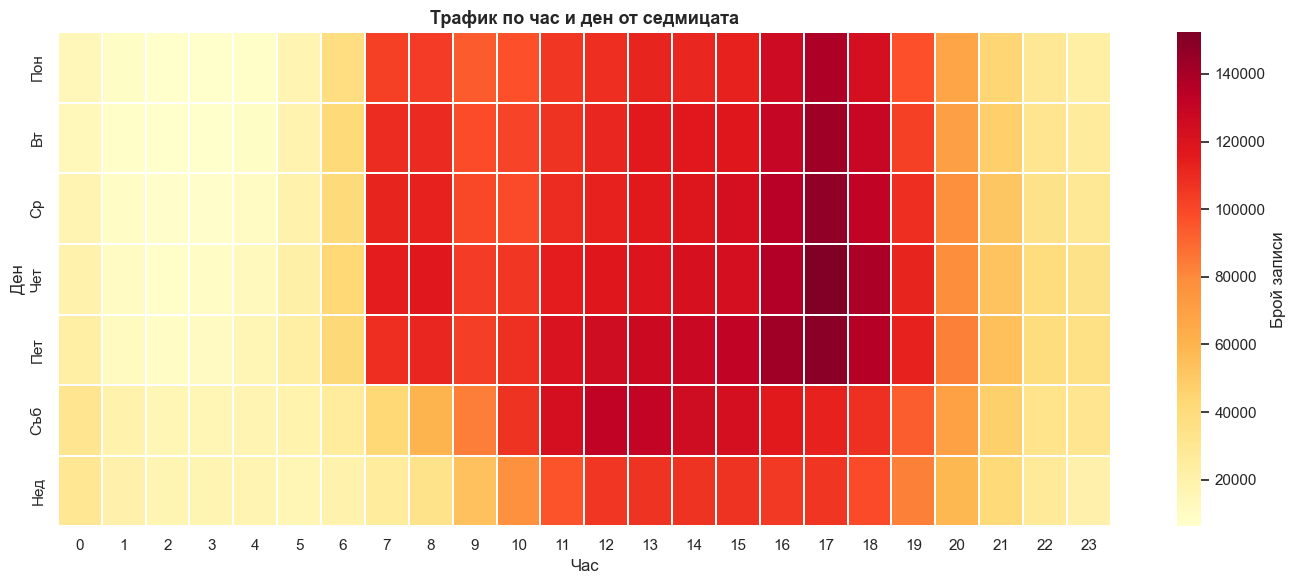

In [17]:
# --- Визуализация 9: Heatmap час x ден от седмицата ---
fig, ax = plt.subplots(figsize=(14, 6))

heatmap_data = (df.groupby(["dow", "hour"])
                  .size()
                  .reset_index(name="count"))

heatmap_pivot = heatmap_data.pivot(index="dow", columns="hour", values="count")
heatmap_pivot.index = ["Пон","Вт","Ср","Чет","Пет","Съб","Нед"]

sns.heatmap(
    heatmap_pivot,
    ax=ax,
    cmap="YlOrRd",
    fmt=",",
    linewidths=0.3,
    cbar_kws={"label": "Брой записи"}
)

ax.set_title("Трафик по час и ден от седмицата", fontsize=13, fontweight="bold")
ax.set_xlabel("Час")
ax.set_ylabel("Ден")

plt.tight_layout()
plt.savefig("viz_09_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

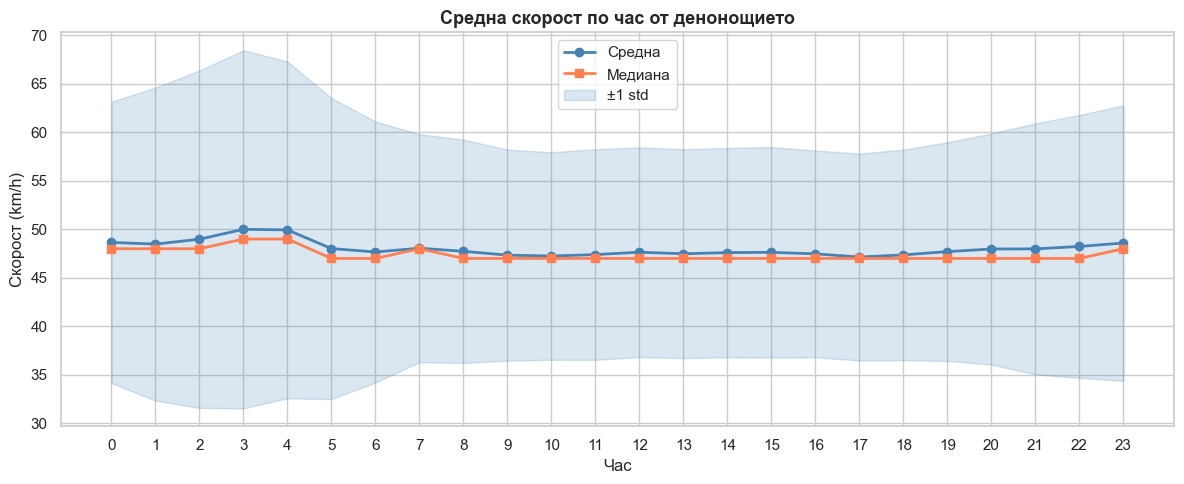

Скорост по час (средна и медиана):
 hour  mean  median  std
    0  48.7    48.0 14.5
    1  48.5    48.0 16.1
    2  49.0    48.0 17.4
    3  50.0    49.0 18.5
    4  49.9    49.0 17.4
    5  48.0    47.0 15.5
    6  47.7    47.0 13.5
    7  48.1    48.0 11.8
    8  47.7    47.0 11.5
    9  47.3    47.0 10.9
   10  47.2    47.0 10.7
   11  47.4    47.0 10.8
   12  47.6    47.0 10.8
   13  47.5    47.0 10.8
   14  47.6    47.0 10.8
   15  47.6    47.0 10.9
   16  47.5    47.0 10.7
   17  47.1    47.0 10.7
   18  47.4    47.0 10.8
   19  47.7    47.0 11.3
   20  48.0    47.0 11.9
   21  48.0    47.0 12.9
   22  48.2    47.0 13.5
   23  48.6    48.0 14.2


In [18]:
# --- Визуализация 10: Средна скорост по час ---
fig, ax = plt.subplots(figsize=(12, 5))

speed_by_hour = (df[(df["speed"] > 0) & (df["speed"] < 255)]
                 .groupby("hour")["speed"]
                 .agg(["mean", "median", "std"])
                 .reset_index())

ax.plot(speed_by_hour["hour"], speed_by_hour["mean"], 
        marker="o", linewidth=2, color="steelblue", label="Средна")
ax.plot(speed_by_hour["hour"], speed_by_hour["median"], 
        marker="s", linewidth=2, color="coral", label="Медиана")
ax.fill_between(speed_by_hour["hour"],
                speed_by_hour["mean"] - speed_by_hour["std"],
                speed_by_hour["mean"] + speed_by_hour["std"],
                alpha=0.2, color="steelblue", label="±1 std")

ax.set_title("Средна скорост по час от денонощието", fontsize=13, fontweight="bold")
ax.set_xlabel("Час")
ax.set_ylabel("Скорост (km/h)")
ax.set_xticks(range(0, 24))
ax.legend()

plt.tight_layout()
plt.savefig("viz_10_speed_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

print("Скорост по час (средна и медиана):")
print(speed_by_hour.round(1).to_string(index=False))

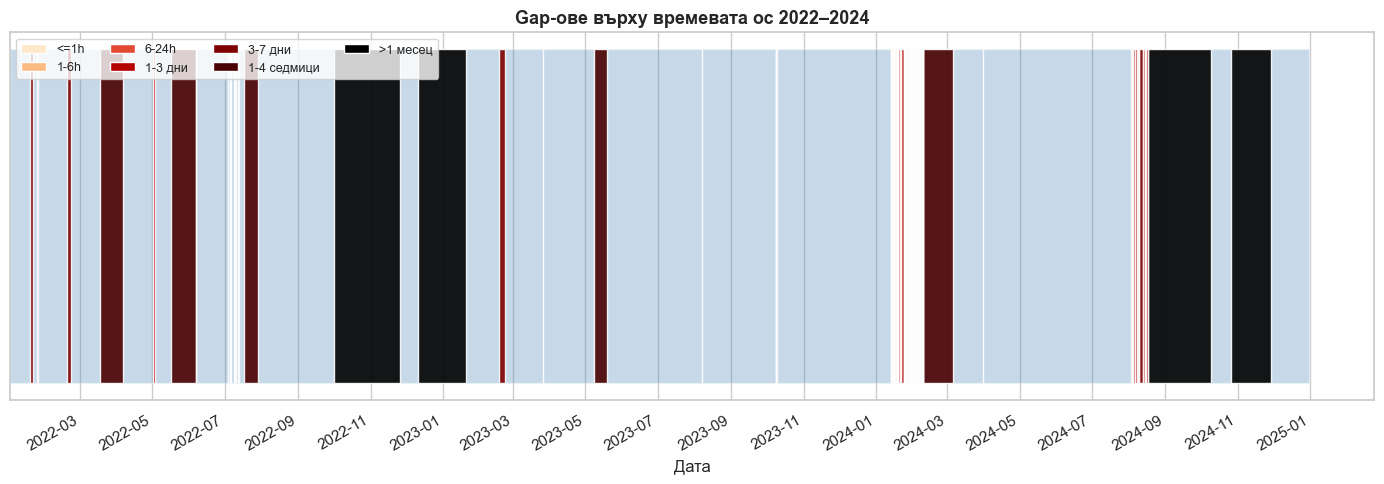

In [19]:
# --- Визуализация 11: Gap-ове визуализирани като блокове ---
fig, ax = plt.subplots(figsize=(14, 5))

# Фон — целият период
ax.barh(0, width=(df["date"].max() - df["date"].min()).days,
        left=df["date"].min(), height=0.4,
        color="steelblue", alpha=0.3, label="Период с данни")

# Gap-овете като червени блокове
colors_map = {
    "<=1h"        : "#fee8c8",
    "1-6h"        : "#fdbb84",
    "6-24h"       : "#e34a33",
    "1-3 дни"     : "#b30000",
    "3-7 дни"     : "#7f0000",
    "1-4 седмици" : "#4a0000",
    ">1 месец"    : "#000000"
}

for _, row in gaps_df.iterrows():
    ax.barh(0,
            width=(row["end"] - row["start"]).total_seconds() / 86400,
            left=row["start"],
            height=0.4,
            color=colors_map[str(row["category"])],
            alpha=0.9)

# Легенда
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=l) 
                   for l, c in colors_map.items()]
ax.legend(handles=legend_elements, loc="upper left", 
          fontsize=9, ncol=4)

ax.set_title("Gap-ове върху времевата ос 2022–2024", 
             fontsize=13, fontweight="bold")
ax.set_xlabel("Дата")
ax.set_yticks([])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("viz_11_gaps_timeline.png", dpi=150, bbox_inches="tight")
plt.show()  

In [20]:
# Анализ на null стойности спрямо регистрационен номер
print("=" * 60)
print("NULL СТОЙНОСТИ СПРЯМО РЕГИСТРАЦИОНЕН НОМЕР")
print("=" * 60)

# Колко уникални номера имат null в direction
plate_null_direction = df[df["direction"].isnull() & df["plate"].notna()]["plate"].nunique()
plate_total = df[df["plate"].notna()]["plate"].nunique()
print(f"\nУникални номера с null в direction : {plate_null_direction:,}")
print(f"Уникални номера общо               : {plate_total:,}")

# Колко уникални номера имат null в country
plate_null_country = df[df["country"].isnull() & df["plate"].notna()]["plate"].nunique()
print(f"\nУникални номера с null в country   : {plate_null_country:,}")

# Има ли номера, които ВИНАГИ имат null country?
plate_country_stats = (df[df["plate"].notna()]
                       .groupby("plate")["country"]
                       .agg(["count", "size"])
                       .rename(columns={"count": "non_null", "size": "total"}))
plate_country_stats["null_count"] = plate_country_stats["total"] - plate_country_stats["non_null"]
plate_country_stats["always_null"] = plate_country_stats["non_null"] == 0
plate_country_stats["sometimes_null"] = (plate_country_stats["null_count"] > 0) & (~plate_country_stats["always_null"])

print(f"\nНомера, при които country е ВИНАГИ null    : {plate_country_stats['always_null'].sum():,}")
print(f"Номера, при които country е ПОНЯКОГА null  : {plate_country_stats['sometimes_null'].sum():,}")
print(f"Номера, при които country е НИКОГА null    : {(plate_country_stats['null_count'] == 0).sum():,}")

# Същото за direction
plate_dir_stats = (df[df["plate"].notna()]
                   .groupby("plate")["direction"]
                   .agg(["count", "size"])
                   .rename(columns={"count": "non_null", "size": "total"}))
plate_dir_stats["null_count"] = plate_dir_stats["total"] - plate_dir_stats["non_null"]
plate_dir_stats["always_null"] = plate_dir_stats["non_null"] == 0

print(f"\nНомера, при които direction е ВИНАГИ null  : {plate_dir_stats['always_null'].sum():,}")

NULL СТОЙНОСТИ СПРЯМО РЕГИСТРАЦИОНЕН НОМЕР

Уникални номера с null в direction : 139,876
Уникални номера общо               : 1,129,032

Уникални номера с null в country   : 503,113

Номера, при които country е ВИНАГИ null    : 277,802
Номера, при които country е ПОНЯКОГА null  : 225,311
Номера, при които country е НИКОГА null    : 625,919

Номера, при които direction е ВИНАГИ null  : 36,627


In [21]:
# Колко записа с null country могат да се попълнят по рег. номер
print("=" * 60)
print("ПОТЕНЦИАЛ ЗА ПОПЪЛВАНЕ НА country ПО РЕГ. НОМЕР")
print("=" * 60)

# Номера с поне едно валидно country
plate_to_country = (df[df["country"].notna() & 
                       df["plate"].notna() & 
                       (df["country"] != "-")]
                    .groupby("plate")["country"]
                    .agg(lambda x: x.mode()[0])  # Най-честата стойност
                    .reset_index()
                    .rename(columns={"country": "country_filled"}))

print(f"Номера с поне 1 валидна държава: {len(plate_to_country):,}")

# Записи с null country, които имат рег. номер и можем да попълним
fillable = (df[df["country"].isnull() & df["plate"].notna()]
            .merge(plate_to_country, on="plate", how="inner"))

print(f"\nЗаписи с null country и познат номер    : {df[df['country'].isnull() & df['plate'].notna()].shape[0]:,}")
print(f"От тях попълними по рег. номер          : {len(fillable):,}")
print(f"Непопълними (няма история за номера)    : {df[df['country'].isnull() & df['plate'].notna()].shape[0] - len(fillable):,}")

# Проверка на точността — за записи с известна държава,
# колко пъти mode() съвпада с реалната стойност?
sample = (df[df["country"].notna() & 
             df["plate"].notna() & 
             (df["country"] != "-")]
          .merge(plate_to_country, on="plate", how="inner"))

accuracy = (sample["country"] == sample["country_filled"]).mean()
print(f"\nТочност на mode() импутацията           : {accuracy*100:.1f}%")

ПОТЕНЦИАЛ ЗА ПОПЪЛВАНЕ НА country ПО РЕГ. НОМЕР
Номера с поне 1 валидна държава: 851,229

Записи с null country и познат номер    : 1,746,925
От тях попълними по рег. номер          : 1,397,258
Непопълними (няма история за номера)    : 349,667

Точност на mode() импутацията           : 85.8%


In [22]:
# Проверка на връзката lane -> direction
print("=" * 60)
print("ВРЪЗКА МЕЖДУ LANE И DIRECTION")
print("=" * 60)

lane_dir = (df[df["direction"].notna()]
            .groupby(["lane", "direction"])
            .size()
            .reset_index(name="count"))

lane_dir_pivot = lane_dir.pivot(index="lane", columns="direction", values="count").fillna(0)
lane_dir_pivot["total"] = lane_dir_pivot.sum(axis=1)

for col in ["Център", "Околовръстно"]:
    lane_dir_pivot[f"{col}_%"] = (lane_dir_pivot[col] / lane_dir_pivot["total"] * 100).round(1)

print(lane_dir_pivot.to_string())

ВРЪЗКА МЕЖДУ LANE И DIRECTION
direction  Околовръстно     Център      total  Център_%  Околовръстно_%
lane                                                                   
L1                  0.0  1475592.0  1475592.0     100.0             0.0
L2                  0.0  4077166.0  4077166.0     100.0             0.0
L3                  0.0   763468.0   763468.0     100.0             0.0
L4            1070725.0        0.0  1070725.0       0.0           100.0
L5            3514639.0        0.0  3514639.0       0.0           100.0
L6             900369.0        0.0   900369.0       0.0           100.0


In [23]:
# Мапинг само за потвърдените ленти
lane_to_direction = {
    "L1": "Център",      "L2": "Център",      "L3": "Център",
    "L4": "Околовръстно", "L5": "Околовръстно", "L6": "Околовръстно"
}

null_dir = df["direction"].isnull()
fillable_dir = null_dir & df["lane"].isin(lane_to_direction.keys())

print(f"Null стойности в direction общо : {null_dir.sum():,}")
print(f"Попълними по lane (L1-L6)       : {fillable_dir.sum():,}")
print(f"Непопълними                     : {(null_dir & ~fillable_dir).sum():,}")

print(f"\nРазпределение на lane при null direction:")
print(df[null_dir]["lane"].value_counts().to_string())

Null стойности в direction общо : 437,569
Попълними по lane (L1-L6)       : 0
Непопълними                     : 437,569

Разпределение на lane при null direction:
lane
LN2    196996
LN5    166816
LN3     38075
LN6     35682


In [24]:
print("=" * 60)
print("АНАЛИЗ НА LN ЗАПИСИ")
print("=" * 60)

ln_mask = df["lane"].str.startswith("LN")

print(f"Общо LN записи: {ln_mask.sum():,}")
print(f"\nСтатистика за LN vs L записи:")

compare = pd.DataFrame({
    "LN (грешка)": df[ln_mask][["speed","length","weight"]].describe().loc[["mean","std","min","max"]].round(1).T.apply(lambda x: x.to_dict(), axis=1),
    "L (нормални)": df[~ln_mask][["speed","length","weight"]].describe().loc[["mean","std","min","max"]].round(1).T.apply(lambda x: x.to_dict(), axis=1)
})

# По-четим формат
for col in ["speed", "length", "weight"]:
    print(f"\n{col}:")
    print(f"  LN : mean={df[ln_mask][col].mean():.1f}, std={df[ln_mask][col].std():.1f}, min={df[ln_mask][col].min()}, max={df[ln_mask][col].max()}")
    print(f"  L  : mean={df[~ln_mask][col].mean():.1f}, std={df[~ln_mask][col].std():.1f}, min={df[~ln_mask][col].min()}, max={df[~ln_mask][col].max()}")

print(f"\nVehicle class разпределение при LN:")
print(df[ln_mask]["vehicle_class"].value_counts().head(10).to_string())

АНАЛИЗ НА LN ЗАПИСИ
Общо LN записи: 437,569

Статистика за LN vs L записи:

speed:
  LN : mean=47.0, std=9.7, min=0, max=255
  L  : mean=47.9, std=13.9, min=0, max=255

length:
  LN : mean=4429.8, std=2085.7, min=0, max=65400
  L  : mean=4102.5, std=2174.8, min=-707100, max=318800

weight:
  LN : mean=2415.7, std=3876.8, min=0, max=132539
  L  : mean=2342.4, std=4456.5, min=-392960, max=907790

Vehicle class разпределение при LN:
vehicle_class
1     374858
0      29472
2      15648
5       7135
23      2618
7       2007
6       1740
3       1516
30       491
35       466
